# Crossover: two parents make two children

`Crossover` combines two parent genotypes into two children. `one_point`, `n_point` and `uniform` decide, gene by gene, which parent each child takes its value from; the second child always takes the other parent's value. `order_crossover` is for permutations, where every value must appear once.

Parents here are all zeros (light) and all ones (dark), so each child's picture shows exactly where it switched parent.

In [1]:
# third-party
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# local
from seachange import Crossover, seed

In [3]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

SEED = 5
GENES = 32
CUTS = 3
PERMUTATION = 10

seed(SEED)

## Three operators on the same parents

`one_point` cuts once and swaps the tails, `n_point` cuts three times and swaps every other segment, `uniform` swaps each gene with probability 0.5. Each pair of rows is one child pair.

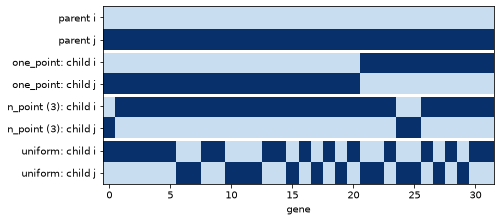

In [4]:
zeros = np.zeros(GENES, dtype=np.int8)
ones = np.ones(GENES, dtype=np.int8)
children = {
    "one_point": Crossover.one_point(zeros, ones),
    "n_point (3)": Crossover.n_point(zeros, ones, CUTS),
    "uniform": Crossover.uniform(zeros, ones),
}
rows = [zeros, ones]
labels = ["parent i", "parent j"]
for name, (child_i, child_j) in children.items():
    rows += [child_i, child_j]
    labels += [f"{name}: child i", f"{name}: child j"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.imshow(np.stack(rows), cmap="Blues", vmin=-0.3, aspect="auto")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("gene")
for edge in np.arange(1.5, len(rows) - 1, 2):
    ax.axhline(edge, color="white", linewidth=3)
plt.show()

In [5]:
switches = {
    name: int(np.count_nonzero(np.diff(child_i)))
    for name, (child_i, _) in children.items()
}
print("parent switches along child i:", switches)
for child_i, child_j in children.values():
    assert np.array_equal(child_i + child_j, ones)
assert switches["one_point"] == 1
assert switches["n_point (3)"] == CUTS

parent switches along child i: {'one_point': 1, 'n_point (3)': 3, 'uniform': 18}


## Arrays keep their shape and dtype

A numpy parent gives numpy children of the same dtype and shape. A 2-D array is crossed over in reading order, row after row, so one cut can fall in the middle of a row.

In [6]:
grid_i = np.zeros((4, 8), dtype=np.float32)
grid_j = np.ones((4, 8), dtype=np.float32)
grid_child, _ = Crossover.one_point(grid_i, grid_j)
print(grid_child.dtype, grid_child.shape)
print(grid_child)
assert grid_child.dtype == np.float32
assert grid_child.shape == grid_i.shape

float32 (4, 8)
[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]]


Lists come back as lists. Their values pass through float64 on the way, so integers come back as floats.

In [7]:
list_child, _ = Crossover.one_point([0, 0, 0, 0], [1, 1, 1, 1])
print(type(list_child).__name__, list_child)
assert isinstance(list_child, list)

list [0.0, 1.0, 1.0, 1.0]


## Order crossover for permutations

Each child keeps one stretch of one parent in place and fills the other positions with the remaining values in the order the other parent has them. Both children are still permutations of 0 to 9.

In [8]:
forward = list(range(PERMUTATION))
backward = forward[::-1]
order_i, order_j = Crossover.order_crossover(forward, backward)
print("parent i:", forward)
print("parent j:", backward)
print("child i: ", order_i)
print("child j: ", order_j)
assert sorted(order_i) == forward
assert sorted(order_j) == forward

parent i: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
parent j: [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
child i:  [9, 8, 2, 3, 4, 5, 6, 7, 1, 0]
child j:  [0, 1, 7, 6, 5, 4, 3, 2, 8, 9]
